# 07 · Batting Performance Analytics

Batting averages, strike rates, scoring patterns, records against pace and spin, and a wagon wheel, all from ball-by-ball data.

Needs: numpy, pandas, matplotlib (`pip install -r notebooks/requirements.txt`).

> Running in Google Colab? Run this once in a new cell first (replace the URL with wherever your copy of the project lives), then run the notebook from the top:
> ```python
> !git clone https://github.com/YOUR-ACCOUNT/pitchvision.git   # or upload and unzip the project folder
> %cd pitchvision
> !pip install -q -r notebooks/requirements.txt
> ```

> About the data. The CSV files in `notebooks/data/` are synthetic: generated by `pitchvision/sample_data.py` with a fixed random seed. The players, matches and numbers are invented so the notebook can run straight away. They are not a real team's results. To use your own data, replace the CSV files with files that have the same columns (see `notebooks/data/DATA_DICTIONARY.md`).

In [1]:
# --- Setup: find the project folder so the shared `pitchvision` package can be imported ---
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "pitchvision").exists():        # the notebook is being run from notebooks/
    ROOT = ROOT.parent
if not (ROOT / "pitchvision").exists():
    raise RuntimeError("Cannot find the 'pitchvision' folder. Open this notebook from inside the PitchVision "
                       "project, or see the Google Colab instructions in notebooks/README.md.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "notebooks" / "data"             # sample CSV files (SYNTHETIC data)
EXPORTS = ROOT / "notebooks" / "exports"       # CSV files written by the notebooks
EXPORTS.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, GREEN, RED, YELLOW = "#0D1310", "#1F6B45", "#B3261E", "#F2C230"
print("Project folder:", ROOT)

Project folder: /Users/sahasreddy/Documents/Cricket


## 1. Definitions

$$\text{batting average} = \frac{\text{runs}}{\text{times out}}\qquad\text{strike rate} = \frac{\text{runs}}{\text{balls faced}}\times 100$$

The average divides by dismissals, so a not-out innings adds runs without adding to the divisor. A batter who has never been out has no average. A wide is not a ball faced; a no-ball is.

In [2]:
from pitchvision import scoring, stats

balls = pd.read_csv(DATA / "balls.csv")
players = pd.read_csv(DATA / "players.csv")
ours = set(players["name"])
print(len(balls), "balls from", balls["match_id"].nunique(), "matches (SYNTHETIC)")
balls.head(3)

1766 balls from 8 matches (SYNTHETIC)


,match_id,innings,batting_team,over,striker,non_striker,bowler,bowl_type,x,y,...,wicket_kind,player_out,fielder,shot_type,shot_angle,synthetic,date,season,format,ball_no
0,1,1,Northfield (synthetic),0,Northfield batter 1,Northfield batter 2,Farhan Ali,pace,0.748,6.096,...,NaN,NaN,NaN,defence,309.6,True,2025-04-26,2025,T20,1
1,1,1,Northfield (synthetic),0,Northfield batter 2,Northfield batter 1,Farhan Ali,pace,-0.038,7.927,...,NaN,NaN,NaN,cut,NaN,True,2025-04-26,2025,T20,2
2,1,1,Northfield (synthetic),0,Northfield batter 2,Northfield batter 1,Farhan Ali,pace,0.242,7.002,...,NaN,NaN,NaN,defence,17.3,True,2025-04-26,2025,T20,3


## 2. From balls to innings

The scoring engine turns each innings' balls into a scorecard. We take the batting line for each of our players in each innings.

In [3]:
lines = scoring.lines_from_balls(balls.to_dict("records"))
batting = pd.DataFrame(lines["batting"])
batting = batting[batting["player"].isin(ours)]
batting[["match_id", "player", "runs", "balls", "fours", "sixes", "out", "how_out"]].head(8)

,match_id,player,runs,balls,fours,sixes,out,how_out
6,1,Arun Mehta,0,2,0,0,True,bowled
7,1,Ben Carter,10,13,2,0,True,caught
8,1,Dev Patel,23,23,3,0,True,caught
9,1,Farhan Ali,16,10,2,1,True,lbw
10,1,Ethan Brooks,0,1,0,0,True,bowled
11,1,Harry Singh,5,12,1,0,True,bowled
12,1,Noah Reid,13,8,3,0,True,caught
13,1,Imran Khan,16,16,1,1,True,caught


In [4]:
# Averages by hand with pandas.
g = batting.groupby("player")
table = pd.DataFrame({"innings": g.size(), "not_outs": g["out"].apply(lambda s: (~s).sum()), "runs": g["runs"].sum(),
                      "balls": g["balls"].sum(), "highest": g["runs"].max(), "fours": g["fours"].sum(), "sixes": g["sixes"].sum()})
table["dismissals"] = table["innings"] - table["not_outs"]
table["average"] = (table["runs"] / table["dismissals"]).where(table["dismissals"] > 0)     # undefined if never out
table["strike_rate"] = (table["runs"] / table["balls"] * 100).where(table["balls"] > 0)
table = table.sort_values("runs", ascending=False)

# The application uses stats.career_batting. The two must agree.
career = {r["player"]: r for r in stats.career_batting(lines["batting"])}
for name, row in table.iterrows():
    c = career[name]
    assert c["runs"] == row["runs"] and c["innings"] == row["innings"]
    assert (c["average"] is None and pd.isna(row["average"])) or abs(c["average"] - row["average"]) < 1e-9
table.round(1)

,innings,not_outs,runs,balls,highest,fours,sixes,dismissals,average,strike_rate
player,,,,,,,,,,
Arun Mehta,7,0,120,94,41,13,4,7,17.1,127.7
Farhan Ali,6,0,115,100,32,8,7,6,19.2,115.0
Dev Patel,8,0,91,79,39,10,2,8,11.4,115.2
Harry Singh,8,1,82,96,22,8,3,7,11.7,85.4
George Hill,7,1,71,76,31,7,3,6,11.8,93.4
Ethan Brooks,6,0,67,78,25,6,1,6,11.2,85.9
Milan Das,6,0,59,79,27,6,2,6,9.8,74.7
Ben Carter,6,0,56,51,19,7,1,6,9.3,109.8
Noah Reid,6,0,44,49,16,5,1,6,7.3,89.8


## 3. How each innings went

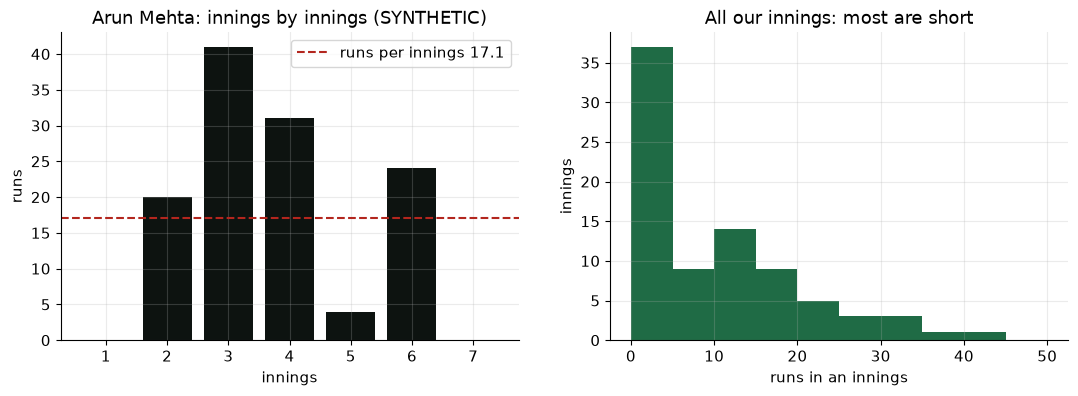

Median innings 6 runs; mean 9.6. The mean is pulled up by a few big scores.


In [5]:
top = table.index[0]
scores = batting[batting["player"] == top]["runs"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(range(1, len(scores) + 1), scores, color=INK)
axes[0].axhline(np.mean(scores), color=RED, ls="--", label=f"runs per innings {np.mean(scores):.1f}")
axes[0].set_xlabel("innings"); axes[0].set_ylabel("runs"); axes[0].set_title(f"{top}: innings by innings (SYNTHETIC)"); axes[0].legend()
axes[1].hist(batting["runs"], bins=range(0, int(batting["runs"].max()) + 10, 5), color=GREEN)
axes[1].set_xlabel("runs in an innings"); axes[1].set_ylabel("innings"); axes[1].set_title("All our innings: most are short")
plt.show()
print(f"Median innings {batting['runs'].median():.0f} runs; mean {batting['runs'].mean():.1f}. The mean is pulled up by a few big scores.")

## 4. How the runs were scored

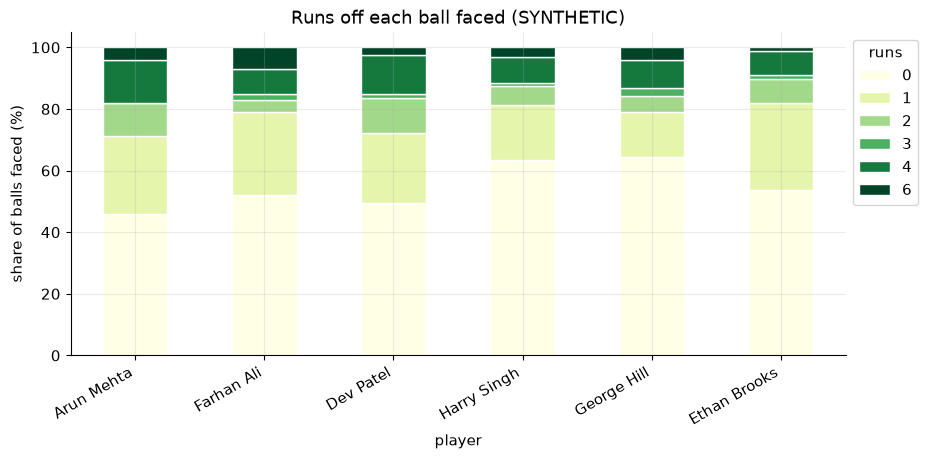

Share of runs in boundaries:
player
Arun Mehta      63.0
Farhan Ali      64.0
Dev Patel       57.0
Harry Singh     61.0
George Hill     65.0
Ethan Brooks    45.0


In [6]:
faced = balls[balls["striker"].isin(ours) & (balls["wides"] == 0)]
mix = faced.groupby("striker")["runs_bat"].value_counts(normalize=True).unstack(fill_value=0) * 100
mix = mix.reindex(table.index[:6])
mix.plot(kind="bar", stacked=True, figsize=(10, 4.2), colormap="YlGn", edgecolor="white")
plt.ylabel("share of balls faced (%)"); plt.title("Runs off each ball faced (SYNTHETIC)"); plt.legend(title="runs", bbox_to_anchor=(1, 1)); plt.xticks(rotation=30, ha="right"); plt.show()

boundary = (table["fours"] * 4 + table["sixes"] * 6) / table["runs"] * 100
print("Share of runs in boundaries:"); print(boundary.head(6).round(0).to_string())

## 5. Against pace and spin, and by length

A split is only interpreted when there are enough balls behind it. With a dozen balls, one boundary changes the strike rate by more than 30 points.

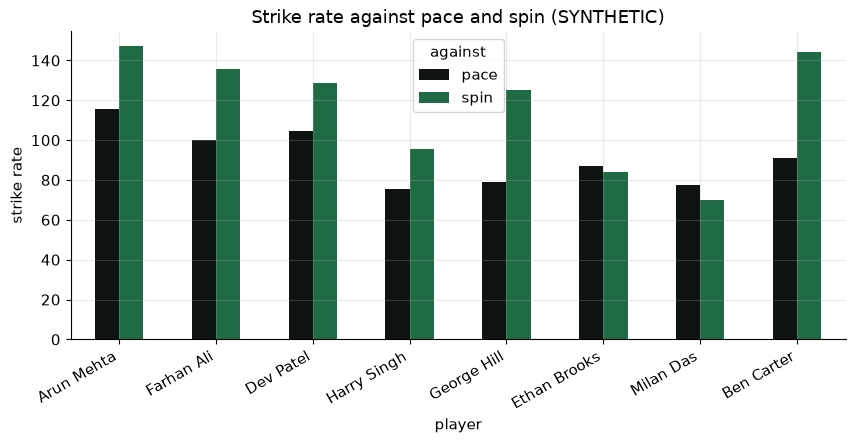

,player,against,balls,runs,outs,strike_rate,average
0,Arun Mehta,pace,58,67,6,115.5,11.2
1,Arun Mehta,spin,36,53,1,147.2,53.0
2,Farhan Ali,pace,58,58,3,100.0,19.3
3,Farhan Ali,spin,42,57,3,135.7,19.0
4,Dev Patel,pace,44,46,5,104.5,9.2
5,Dev Patel,spin,35,45,3,128.6,15.0
6,Harry Singh,pace,49,37,3,75.5,12.3
7,Harry Singh,spin,47,45,4,95.7,11.2
8,George Hill,pace,52,41,5,78.8,8.2
9,George Hill,spin,24,30,1,125.0,30.0


In [7]:
rows = []
for name in table.index[:8]:
    sp = stats.batting_splits(balls.to_dict("records"), name)
    for kind in ("pace", "spin"):
        d = sp["bowl_type"].get(kind)
        if d:
            rows.append({"player": name, "against": kind, "balls": d["balls"], "runs": d["runs"], "outs": d["dismissals"],
                         "strike_rate": d["strike_rate"], "average": d["average"]})
splits = pd.DataFrame(rows)
pivot = splits.pivot(index="player", columns="against", values="strike_rate").reindex(table.index[:8])
pivot.plot(kind="bar", color=[INK, GREEN], figsize=(10, 4)); plt.ylabel("strike rate"); plt.title("Strike rate against pace and spin (SYNTHETIC)")
plt.xticks(rotation=30, ha="right"); plt.show()
splits.round(1)

In [8]:
sp = stats.batting_splits(balls.to_dict("records"), top)
by_length = pd.DataFrame(sp["length"]).T.reindex(["yorker", "full", "good", "short", "bouncer"]).dropna(how="all")
print(top, "by length of delivery:")
display(by_length[["balls", "runs", "dismissals", "strike_rate", "dot_pct"]].astype(float).round(1))
by_shot = pd.DataFrame(sp["shot_type"]).T.sort_values("runs", ascending=False)
print(top, "by shot played:"); by_shot[["balls", "runs", "dismissals", "strike_rate"]].astype(float).round(1)

Arun Mehta by length of delivery:


,balls,runs,dismissals,strike_rate,dot_pct
yorker,1.0,0.0,1.0,0.0,100.0
full,48.0,59.0,4.0,122.9,39.6
good,28.0,31.0,1.0,110.7,57.1
short,16.0,30.0,1.0,187.5,37.5
bouncer,1.0,0.0,0.0,0.0,100.0


Arun Mehta by shot played:


,balls,runs,dismissals,strike_rate
drive,34.0,45.0,0.0,132.4
flick,11.0,25.0,0.0,227.3
defence,18.0,24.0,0.0,133.3
pull,7.0,13.0,0.0,185.7
cut,9.0,10.0,0.0,111.1
loft,2.0,2.0,0.0,100.0
glance,5.0,1.0,0.0,20.0
NaN,8.0,0.0,7.0,0.0


## 6. Wagon wheel

Each scoring shot has an angle. 0 degrees is straight back past the bowler, and angles grow clockwise toward the off side, so 90 is square on the off side and 270 square on the leg side. The ground is split into eight 45-degree zones.

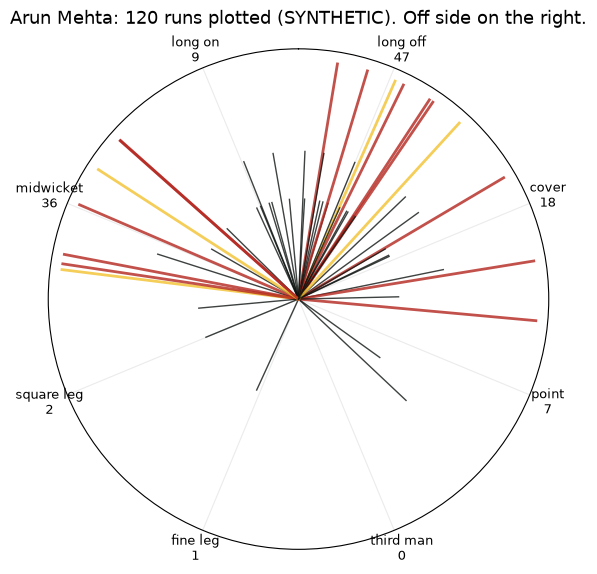

Off side 60%, leg side 40%. Strongest zones: long_off, midwicket, cover
Shots with no recorded direction: 0


In [9]:
shots = balls[(balls["striker"] == top) & balls["shot_angle"].notna()]
wheel = stats.wagon_wheel(shots.to_dict("records"))

fig = plt.figure(figsize=(6.5, 6.5)); ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)          # 0 at the top, clockwise
reach = {1: 0.42, 2: 0.62, 3: 0.78, 4: 1.0, 6: 1.0}
for s in wheel["shots"]:
    ax.plot([np.radians(s["angle"])] * 2, [0, reach.get(s["runs"], 0.3)], color=YELLOW if s["runs"] == 6 else RED if s["runs"] == 4 else INK,
            lw=2 if s["runs"] >= 4 else 1, alpha=0.8)
ax.set_xticks(np.radians(np.arange(22.5, 360, 45)))
ax.set_xticklabels([f"{z['zone'].replace('_', ' ')}\n{z['runs']}" for z in wheel["zones"]], fontsize=9)
ax.set_yticks([]); ax.set_ylim(0, 1.05); ax.set_title(f"{top}: {wheel['total_runs']} runs plotted (SYNTHETIC). Off side on the right.", pad=18)
plt.show()
print(f"Off side {wheel['off_side_pct']:.0f}%, leg side {wheel['leg_side_pct']:.0f}%. Strongest zones: {', '.join(wheel['strong_zones'])}")
print("Shots with no recorded direction:", wheel["unplotted"])
table.round(2).to_csv(EXPORTS / "batting_summary.csv")

## Summary

### Key findings
- Averages and strike rates built with pandas match `stats.career_batting` for every player.
- Most innings are short and a few are long, so runs per innings sits above the median.
- Splits by bowling type, length and shot come straight from the ball records, and each carries its ball count.

### Interpretation
An average over six or seven innings is a rough guide. One more not-out or one more duck moves it a long way. Look at the ball counts before reading anything into a split.

### Limitations
- Averages mean little before about ten dismissals.
- Strike rate ignores the match situation: a slow innings can be the right one.
- Shot type and direction depend on the scorer's judgement.
- Synthetic data: the patterns reflect how the generator works, not real batters.

### How this notebook connects to the application
Team Hub player profiles and leaderboards use `stats.career_batting` on lines produced by the scoring engine. The Batting Lab's Shot selection tab calls `stats.batting_splits` through `GET /api/stats/splits`, and the Wagon wheel tab calls `stats.wagon_wheel` through `GET /api/stats/wagon`.